## Demo Diffusion models generative AI

Author: alberto.suarez@uam.es
Date: 2025-03-02

In [1]:
%load_ext autoreload
%autoreload 2

import numpy as np

from functools import partial 

import torch
from torch.utils.data import (
    DataLoader,
    Dataset,
    Subset,
)
from torchvision import datasets
from torchvision.transforms import ToTensor
from torchvision.transforms import functional

import diffusion_process as dfp
import difussion_process_conditional as dfpc
import ode as ode
import ode_condicional as odec


from diffusion_utilities import (
    plot_image_grid,
    plot_image_evolution,
    animation_images,
    colorize_mnist
)


n_threads = torch.get_num_threads()
print('Number of threads: {:d}'.format(n_threads))

device ='cuda' #with cuda should be faster
#device ='cpu' 

colored = False

Number of threads: 6


In [2]:
import torchvision.transforms as T
if not colored:
    transform = ToTensor()
    n_channels = 1
else:
    # Convierte a (1, H, W) y luego colorea a (3, H, W)
    transform = T.Compose([
        ToTensor(),
        T.Lambda(colorize_mnist),
    ])
    n_channels = 3
data = datasets.MNIST(
    root='data',
    train=True,
    download=True,
    transform=transform,
)
print(type(data))

<class 'torchvision.datasets.mnist.MNIST'>


In [3]:
# Configurar el dataset de entrenamiento
# Opción 1: Entrenar con TODOS los dígitos (0-9) - más diversidad
data_train = data  # Usar todo el dataset

# Opción 2 (alternativa): Entrenar con dígitos específicos
# digit1 = 3
# digit2 = 8
# indices_digit = torch.where(
#     (data.targets == digit1) | (data.targets == digit2)
# )[0]
# from torch.utils.data import Subset
# data_train = Subset(data, indices_digit)

print(f'Tamaño del dataset de entrenamiento: {len(data_train)}')
print(type(data_train))

Tamaño del dataset de entrenamiento: 60000
<class 'torchvision.datasets.mnist.MNIST'>


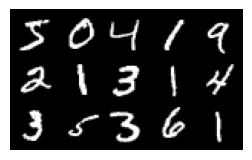

In [4]:
# Visualize training images
n_rows = 3 
n_cols = 5

_ = plot_image_grid(
    images=[data_train[i][0] for i in range(n_rows * n_cols)],
    figsize =(3, 3),
    n_rows=n_rows, 
    n_cols=n_cols,
)

###  Diffusion process

In [5]:
sigma_min = 0.01
sigma_max = 25.0
r = 0.5  # Decay rate for exponential mean

def bm_drift_coefficient(x_t, t):
    """Drift: f(x,t) = -r·x  (Ornstein-Uhlenbeck)"""
    return -r * x_t

def bm_sigma_t(t):
    """VE marginal σ(t) = σ_min · (σ_max/σ_min)^t"""
    if not torch.is_tensor(t):
        t = torch.tensor(t, dtype=torch.float32)
    t = t.float()
    return sigma_min * (sigma_max / sigma_min) ** t

def bm_diffusion_coefficient(t):
    """Diffusion g(t) = σ(t) · √(2·log(σ_max/σ_min))"""
    if not torch.is_tensor(t):
        t = torch.tensor(t, dtype=torch.float32)
    sigma_t_val = bm_sigma_t(t)
    log_ratio = torch.log(torch.tensor(sigma_max / sigma_min,
                                       dtype=torch.float32,
                                       device=t.device))
    result = sigma_t_val * torch.sqrt(2.0 * log_ratio)
    return result.view(-1, 1, 1, 1)

def bm_mu_t(x_0, t):
    """Mean: μ(x₀, t) = x₀ · exp(-r·t)"""
    if not torch.is_tensor(t):
        t = torch.tensor(t, dtype=torch.float32)
    t = t.float()
    # Reshape for broadcasting: t from (batch,) to (batch,1,1,1)
    if t.ndim > 0:
        t = t.view(-1, *([1] * (x_0.ndim - 1)))
    return x_0 * torch.exp(-r * t)


def ve_marginal_prob_std(t):
    return bm_sigma_t(t)

drift_coefficient = bm_drift_coefficient
diffusion_coefficient = bm_diffusion_coefficient
mu_t = bm_mu_t
sigma_t = bm_sigma_t


diffusion_process = dfpc.GaussianDiffussionProcess(
    drift_coefficient,
    diffusion_coefficient,
    mu_t,
    sigma_t,
)


In [6]:
# Define the score model

from score_model import ScoreNet

score_model = torch.nn.DataParallel(
    ScoreNet(
        marginal_prob_std=ve_marginal_prob_std,
        num_classes=10,
        input_channels=n_channels
    )
)
score_model = score_model.to(device)

In [25]:
# Train model
from torch.optim import Adam
from torch.optim.lr_scheduler import StepLR
import torchvision.transforms as transforms
from tqdm.auto import tqdm, trange

batch_size = 32
data_loader = DataLoader(
    data_train, 
    batch_size=batch_size, 
    shuffle=True, 
    num_workers=n_threads,
)


checkpoint = torch.load('check_point_VE.pth')
score_model.load_state_dict(checkpoint)

#  [TO DO: Comment each line of code]
#establish learning rate, which controls the size of the weights
learning_rate = 1e-3  
# We create Adam optimizer which adjusts automatically the learning rate for each parameter. 
# score_model, tells the optimizer which weights to use
# lr, defines the learning rate
optimizer = Adam(score_model.parameters(), lr=learning_rate)
# Learning rate scheduler: reduce LR by factor 0.5 every 100 epochs for fine-tuning
scheduler = StepLR(optimizer, step_size=100, gamma=0.5)

n_epochs = 50  # More epochs needed for 3-channel colorized MNIST
tqdm_epoch = trange(n_epochs) #creates a progress bar to see the progress of the training
best_loss = float('inf')
for epoch in tqdm_epoch: 
    avg_loss = 0.0 #Initial average loss
    num_items = 0 #Number of images processed in an epoch
    for x, y in data_loader: #for each batch in the data_loader
        x = x.to(device) #images to cpu or gpu for PyTorch to process them
        y = y.to(device)
        loss = diffusion_process.loss_function(score_model, x, y) #loss for the batch
        optimizer.zero_grad() #reboot gradients to zero (if not they accumulate)
        loss.backward() #calculates the loss gradients in respect of all the parameters
        # Gradient clipping to prevent exploding gradients
        torch.nn.utils.clip_grad_norm_(score_model.parameters(), max_norm=1.0)
        optimizer.step() #updates the parameters using the gradient
        avg_loss += loss.item() * x.shape[0] #Sum of total loss
        num_items += x.shape[0] #Sum of all the images processed
    
    scheduler.step()  # Adjust learning rate
    epoch_loss = avg_loss / num_items
    #Updates the progress bar showing the mean loss
    tqdm_epoch.set_description('Average Loss: {:5f}, LR: {:.2e}'.format(epoch_loss, scheduler.get_last_lr()[0]))
    # Save checkpoint only when loss improves (best model selection)
    if epoch_loss < best_loss:
        best_loss = epoch_loss
        torch.save(score_model.state_dict(), 'check_point_VE.pth')


Average Loss: 0.049889, LR: 1.00e-03: 100%|██████████| 50/50 [15:08<00:00, 18.18s/it]


In [46]:
# Sample from the trained model

n_images = 10

check_point = torch.load('check_point_VE.pth', map_location=device)
score_model.load_state_dict(check_point)

T = 1.0
image_T = torch.randn(n_images, n_channels, 28, 28).to(device) * sigma_t(T)

y = torch.tensor([i for i in range(10)], device=device)

# VE-SDE sampling notes:
# sigma_max=25 con t_end=1e-3 da sigma_residual = sigma_min ≈ 0.01
# n_steps=2000 garantiza estabilidad numérica con el esquema Euler
# clip=True aplica clamping a [0,1] en la imagen final

with torch.no_grad():
    times, synthetic_images_t = odec.pf_ode(
        y = y,
        model = score_model,
        x_T = image_T,
        t_0 = T,
        t_end = 1e-3,
        n_steps = 2000,
        drift_coefficient = drift_coefficient,
        diffusion_coefficient = diffusion_coefficient,
        clip = True,  # Clamp final images to [0,1]
    )

# Diagnostic: check pixel statistics of final images
final = synthetic_images_t[..., -1]
print(f'Shape: {synthetic_images_t.shape}')
print(f'Final images - min: {final.min():.4f}, max: {final.max():.4f}, mean: {final.mean():.4f}')
in_range = ((final >= 0) & (final <= 1)).float().mean()
print(f'Pixels in [0,1]: {in_range:.2%}')


Shape: torch.Size([10, 1, 28, 28, 2001])
Final images - min: 0.0000, max: 1.0000, mean: 0.1883
Pixels in [0,1]: 100.00%


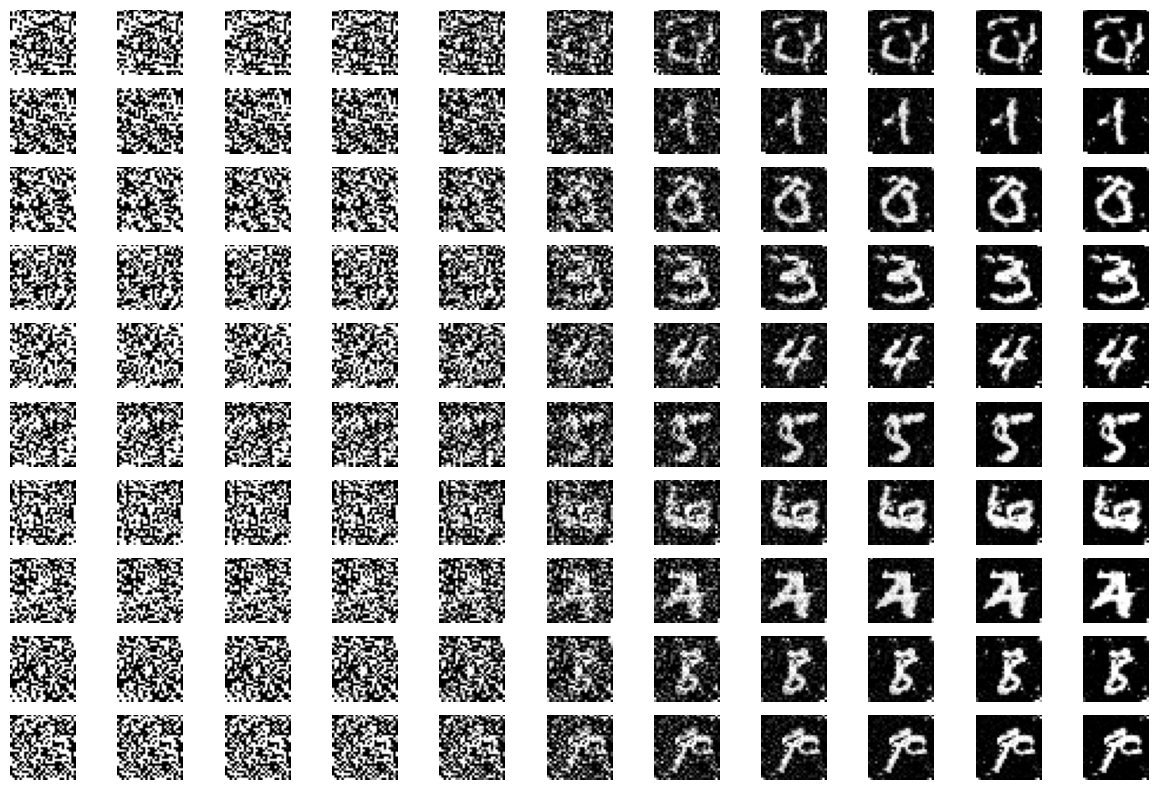

In [47]:
_ = plot_image_evolution(
    images=synthetic_images_t.detach().cpu(),
    n_images=n_images,
    # Pasos para n_steps=2000 (t va de 1.0 → 0.001)
    n_intermediate_steps=[0, 200, 400, 600, 800, 1000, 1200, 1400, 1600, 1800, 2000],
    figsize=(15, 10),
)


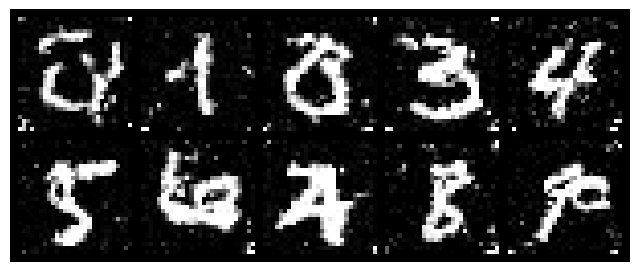

In [48]:
n_rows = 2
n_cols = 5
final_images = synthetic_images_t[..., -1].detach().cpu()
_ = plot_image_grid(
    images = final_images,
    figsize =(8, 4),
    n_rows=n_rows, 
    n_cols=n_cols,
    enhance_contrast=True,
    gamma=0.8,
)

In [ ]:
final_images = synthetic_images_t[..., -1]

with torch.no_grad():
    bpd_values = odec.compute_bpd_with_ode(
        model=score_model,
        x=final_images, 
        drift_coefficient=bm_drift_coefficient,  
        diffusion_coefficient=diffusion_coefficient,
        sigma_t_func=bm_sigma_t,  
        y=y,
        n_steps=100,  
        seed=42
    )

print(f"\nBPD mean: {bpd_values.mean().item():.4f}")
print(f"BPD std: {bpd_values.std().item():.4f}")


BPD mean: 4.7725
BPD std: 0.2011
